# Week 3: Sketch to image

To start, save a copy to your Drive (File, then Save a copy in Drive), then run the cells in order. It runs on Colab's free CPU runtime, since the images are made on Replicate. You will need the course Replicate token, which you can add in Colab's Secrets panel (the key icon on the left) with the name REPLICATE_API_TOKEN. The outputs below are from the chair sketch in the week 3 slides.

## 1. Setup

This reads your Replicate token from Colab's Secrets. If it is not there, it will ask you to paste it.

In [1]:
import base64, io, os, sys, time
IN_COLAB = "google.colab" in sys.modules
import requests
from PIL import Image, ImageOps
from IPython.display import display

token = os.environ.get("REPLICATE_API_TOKEN")
if IN_COLAB and not token:
    try:
        from google.colab import userdata
        token = userdata.get("REPLICATE_API_TOKEN")
    except Exception:
        token = None
if not token:
    import getpass
    token = getpass.getpass("Replicate token: ")
HEADERS = {"Authorization": f"Bearer {token}", "Content-Type": "application/json"}
EXAMPLE = "https://raw.githubusercontent.com/chuanenlin/mlfordesign/main/examples/chair-sketch/"
print("ready")

ready


## 2. Your sketch

With USE_EXAMPLE = True, it downloads the chair sketch from the slides. To use your own, set it to False and run the cell again. It will ask for a photo of your sketch, and it turns the photo into dark lines on white.

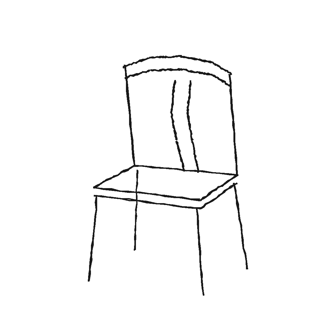

In [2]:
USE_EXAMPLE = True  # True: the chair sketch from the week 3 slides. False: upload a photo of your own sketch.

def clean_sketch(im):
    """Turn a photo of a pencil or pen sketch into dark lines on white, on a square canvas."""
    g = ImageOps.autocontrast(ImageOps.grayscale(ImageOps.exif_transpose(im)), cutoff=2)
    g = g.point(lambda v: 0 if v < 140 else 255)
    side = max(g.size)
    canvas = Image.new("L", (side, side), 255)
    canvas.paste(g, ((side - g.width) // 2, (side - g.height) // 2))
    return canvas.resize((1024, 1024)).convert("RGB")

def get_sketch(example_name):
    if USE_EXAMPLE:
        name = example_name
        if not os.path.exists(name):
            open(name, "wb").write(requests.get(EXAMPLE + name, timeout=60).content)
        return Image.open(name).convert("RGB")
    from google.colab import files
    data = next(iter(files.upload().values()))
    return clean_sketch(Image.open(io.BytesIO(data)))

sketch = get_sketch("sketch.png")
sketch.save("my-sketch.png")
display(sketch.resize((320, 320)))

## 3. Your prompt

Write what the design is and what it is made of, for example "a side chair for a museum cafe, oak". The sketch sets the shape, so the words mostly change the material and colour.

In [3]:
PROMPT = "a side chair for a museum cafe, oak, product photo on a plain grey backdrop"
SEEDS = [1, 2, 3, 4]

## 4. Make the images

It makes one image for each seed with FLUX.1 Canny [dev], a model that follows the edges in your sketch. Each image takes about 15 seconds and costs about 2.5 US cents.

seed 1 done


seed 2 done


seed 3 done


seed 4 done


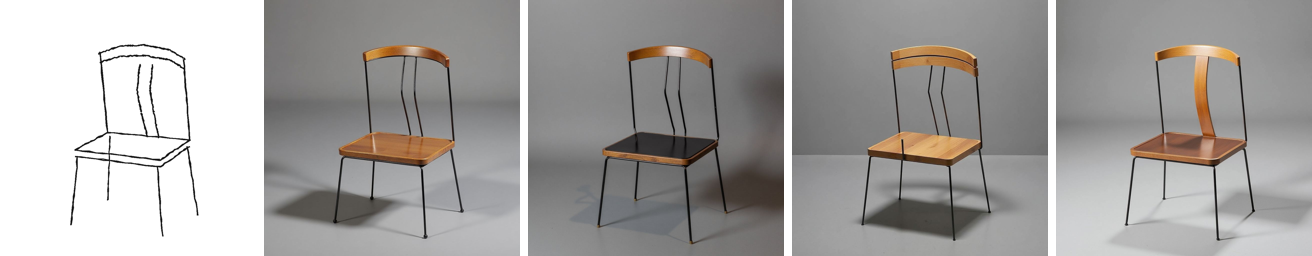

In [4]:
def sketch_to_image(sk, prompt, seed):
    """One image from FLUX.1 Canny [dev] on Replicate, which follows the edges of the sketch."""
    buf = io.BytesIO(); sk.save(buf, format="PNG")
    inp = {"prompt": prompt, "seed": seed, "output_format": "jpg",
           "control_image": "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()}
    r = requests.post("https://api.replicate.com/v1/models/black-forest-labs/flux-canny-dev/predictions",
                      headers=HEADERS, json={"input": inp}, timeout=300).json()
    while r.get("status") not in ("succeeded", "failed", "canceled"):
        time.sleep(2)
        r = requests.get(r["urls"]["get"], headers=HEADERS, timeout=60).json()
    if r["status"] != "succeeded":
        raise RuntimeError(r.get("error"))
    url = r["output"][0] if isinstance(r["output"], list) else r["output"]
    return Image.open(io.BytesIO(requests.get(url, timeout=120).content)).convert("RGB")

def row(images, size=256):
    out = Image.new("RGB", (len(images) * (size + 8) - 8, size), "white")
    for i, im in enumerate(images):
        out.paste(im.resize((size, size)), (i * (size + 8), 0))
    return out

results = []
for s in SEEDS:
    im = sketch_to_image(sketch, PROMPT, s)
    im.save(f"image-seed-{s}.jpg")
    results.append(im)
    print(f"seed {s} done")
row([sketch] + results)

## 5. Change one thing and run again

With USE_EXAMPLE = True, it uses the same chair with the legs drawn as outlined bars. With your own sketch, it will ask for a photo of the changed sketch. It runs the first seed again so you can compare the two. For the hand-in, you can download both sketches and their images from the Files panel on the left.

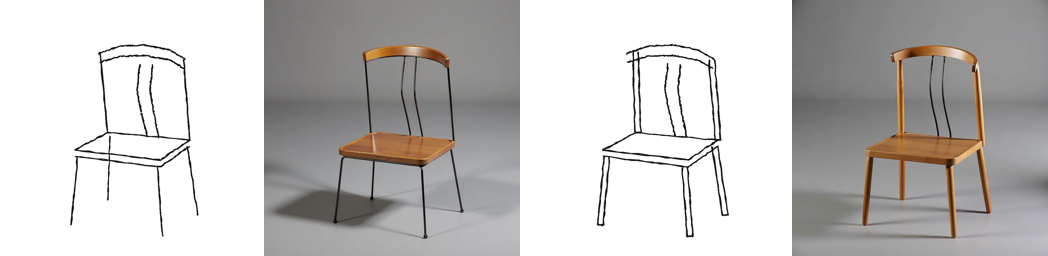

In [5]:
sketch2 = get_sketch("sketch2.png")
sketch2.save("my-sketch-2.png")
again = sketch_to_image(sketch2, PROMPT, SEEDS[0])
again.save(f"image-2-seed-{SEEDS[0]}.jpg")
row([sketch, results[0], sketch2, again])